# 03 · CNN: frozen vs fine-tuned, chosen on validation

**Question.** Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage?

**What this notebook adds.** The template froze an ImageNet ResNet-18 and trained only the last layer — on a split that leaked patients. Here I run that same frozen model on the clean split, then unfreeze the whole network (plain, and with light augmentation) and pick between the three configurations on validation only.

**Hypothesis.** Fine-tuning the whole ResNet-18 at 224 px raises specificity well above the frozen model's, at sensitivity >= 95 %.

**Feeds report sections 3 (methods), 4 (experiments) and 5 (results, limitations).**

## Setup
Same pattern as notebooks 01/02: find data and the patient split, set outputs, print versions and the device.

Note: training on MPS (or CUDA) is fast but not bit-exact reproducible — small numeric differences between runs are expected even with the same seed.

In [1]:
import csv, copy, json, re, sys, time, zipfile, platform, shutil
from collections import Counter
from pathlib import Path
import requests
import numpy as np, matplotlib.pyplot as plt, torch
import torch.nn.functional as F
from torch import nn
from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights
import torchvision.transforms.v2 as v2

# works locally or on Colab: ROOT/DATA_DIR point at the repo or /content
IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content") if IN_COLAB else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
DATA_DIR = Path("/content/chest_xray") if IN_COLAB else ROOT / "data/chest_xray"
ZIP = Path("/content/ChestXRay2017.zip") if IN_COLAB else ROOT / "data/ChestXRay2017.zip"
URL = "https://data.mendeley.com/public-files/datasets/rscbjbr9sj/files/f12eaf6d-6023-432f-acc9-80c9d7393433/file_downloaded"
# fetch and unzip the data only if it is missing
if not (DATA_DIR / "train").exists():
    ZIP.parent.mkdir(parents=True, exist_ok=True)
    if not ZIP.exists():
        print("downloading", URL)
        with requests.get(URL, headers={"User-Agent": "Mozilla/5.0"}, stream=True, timeout=60) as resp:
            resp.raise_for_status()
            with open(ZIP, "wb") as f:
                shutil.copyfileobj(resp.raw, f, 1 << 20)
    print("unzipping", ZIP)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(ZIP.parent)
OUT = ROOT / "results/own"; OUT.mkdir(parents=True, exist_ok=True)
SPLITS = ROOT / "splits"
# the chosen checkpoint is saved to data/models/03_final.pt for notebook 04
MODELS_DIR = Path("/content/models") if IN_COLAB else ROOT / "data/models"; MODELS_DIR.mkdir(parents=True, exist_ok=True)
SEED = 0

# split_file = SPLITS / "patient_split.csv"
# trained on Colab, so the split CSV is read from /content, not SPLITS
split_file = Path("/content/patient_split.csv")
if not split_file.exists():
    if IN_COLAB:
        r = requests.get("https://raw.githubusercontent.com/ashok-rai/bia-pediatric-pneumonia-cxr/main/splits/patient_split.csv",
                         timeout=120); r.raise_for_status()
        SPLITS.mkdir(exist_ok=True); split_file.write_text(r.text)
        print("downloaded patient_split.csv from GitHub")
    else:
        raise FileNotFoundError(f"{split_file} missing - run notebooks/01_patient_split_audit.ipynb first")

# prefer GPU; note MPS/CUDA runs are not bit-exact between runs
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
# log library versions for the reproducibility section
import sklearn
print("python", platform.python_version(), "| torch", torch.__version__.split("+")[0],
      "| numpy", np.__version__, "| sklearn", sklearn.__version__)
print("device =", device, "| ROOT =", ROOT)

downloading https://data.mendeley.com/public-files/datasets/rscbjbr9sj/files/f12eaf6d-6023-432f-acc9-80c9d7393433/file_downloaded
unzipping /content/ChestXRay2017.zip
python 3.13.16 | torch 2.14.1 | numpy 2.4.6 | sklearn 1.6.1
device = cuda | ROOT = /content


## a · Images at two resolutions
The frozen model reuses `cache_128.npz` and is upsampled to 224 inside the preprocessing, exactly like the template's `prep()` — so config A is the template model on the clean split. The fine-tuned models read the original files at 224 px (`cache_224.npz`, built the same way with the same order check).

In [2]:
from sklearn.metrics import roc_auc_score, roc_curve

# same split file and file order as notebooks 01/02
rows = list(csv.DictReader(open(split_file)))
rows.sort(key=lambda r: r["file"])
files = [r["file"] for r in rows]
y = np.array([int(r["label"]) for r in rows])
split = np.array([r["split"] for r in rows])
CLASSES = ["NORMAL", "PNEUMONIA"]; F_ = 1
IDX = {s: np.where(split == s)[0] for s in ("train", "val", "test")}
print("rows:", len(rows), dict(Counter(split)))

# one image array per resolution, cached; rebuilt only if the file list changed
def load_cache(name):
    p = Path("/content") / name if IN_COLAB else ROOT / "data" / name
    if p.exists() and list(np.load(p)["files"]) == files:
        return np.load(p)["X"]
    size = int(name.split("_")[1].split(".")[0])
    X = np.stack([np.asarray(Image.open(DATA_DIR / f).convert("RGB").resize((size, size), Image.BILINEAR))
                  for f in files])
    np.savez(p, X=X, files=np.array(files))
    return X

# 128 px for the frozen template model, 224 px for fine-tuning
X128 = load_cache("cache_128.npz"); X224 = load_cache("cache_224.npz")
assert list(np.load((ROOT / "data/cache_224.npz") if not IN_COLAB else Path("/content/cache_224.npz"))["files"]) == files
print("X128", X128.shape, "X224", X224.shape)

rows: 5856 {np.str_('test'): 624, np.str_('train'): 4043, np.str_('val'): 732, np.str_('dropped'): 457}
X128 (5856, 128, 128, 3) X224 (5856, 224, 224, 3)


## b · Config A: the template's frozen ResNet-18, verbatim
Body frozen, only `nn.Linear(512, 2)` learns: Adam lr 1e-3, batch 64, 10 epochs, class-weighted cross-entropy (rare class counts more). Features are extracted once; three seeds for the head.

In [3]:
# ImageNet normalisation constants
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def prep(x):                                        # template verbatim: upsample to 224, normalise
    t = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    return (F.interpolate(t, size=(224, 224), mode="bilinear") - MEAN) / STD

def prep224(x):                                     # already 224: just scale + normalise
    return (torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255 - MEAN) / STD

# preprocess in batches to keep memory use bounded
def chunks(Xa, bs, fn):
    return torch.cat([fn(Xa[i:i + bs]).to(device) for i in range(0, len(Xa), bs)])

t0 = time.perf_counter()
# config A: frozen ResNet-18 body, features extracted once, only the head trains
net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).eval().to(device)
body = nn.Sequential(*list(net.children())[:-1])            # everything except the last layer
with torch.no_grad():
    FEAT = torch.cat([body(chunks(X128[i:i + 256], 128, prep)).flatten(1).cpu()
                      for i in range(0, len(X128), 256)])
print(f"features extracted {tuple(FEAT.shape)} in {time.perf_counter() - t0:.0f}s")

# class-weighted loss: the rarer NORMAL class counts more
w = torch.tensor(len(IDX["train"]) / (2 * np.bincount(y[IDX["train"]])), dtype=torch.float32).to(device)

# template recipe for the head: Adam lr 1e-3, batch 64, 10 epochs
def train_head(seed=0, epochs=10):
    torch.manual_seed(seed)
    head = nn.Linear(512, 2).to(device); opt = torch.optim.Adam(head.parameters(), lr=1e-3)
    x, yt = FEAT[IDX["train"]].to(device), torch.tensor(y[IDX["train"]]).long().to(device)
    for _ in range(epochs):
        o = torch.randperm(len(yt))
        for i in range(0, len(o), 64):
            b = o[i:i + 64]; loss = F.cross_entropy(head(x[b]), yt[b], weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
    return head.eval()

# P(pneumonia) on the cached features
def head_probs(head, idx):
    with torch.no_grad():
        return F.softmax(head(FEAT[idx].to(device)), 1)[:, 1].cpu().numpy()

t0 = time.perf_counter()
# three seeds for the head so seed luck is visible
heads = {s: train_head(s) for s in (0, 1, 2)}
P_frozen = {s: head_probs(heads[s], np.arange(len(y))) for s in (0, 1, 2)}
t_frozen = (time.perf_counter() - t0) / 3
print(f"frozen heads trained: 3 seeds, {t_frozen:.0f}s per run")
for s in (0, 1, 2):
    print(f"  seed {s}: val AUC {roc_auc_score(y[IDX['val']], P_frozen[s][IDX['val']]):.3f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 106MB/s]


features extracted (5856, 512) in 20s
frozen heads trained: 3 seeds, 1s per run
  seed 0: val AUC 0.994
  seed 1: val AUC 0.994
  seed 2: val AUC 0.995


## c · Configs B and C: fine-tune the whole network at 224 px
All layers trainable, Adam lr 1e-4, batch 32, up to 8 epochs, same class-weighted loss. After each epoch I measure validation AUC and keep the weights of the best epoch. Config C adds light augmentation on training batches only — small affine shifts and brightness/contrast jitter, done on tensors. **No horizontal flip**: the heart sits on the left, a mirrored chest X-ray is not the same anatomy.

In [4]:
# config C augmentation, applied to [0,1] tensors before normalisation; no flip (the heart sits on the left)
AUG = v2.Compose([v2.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.95, 1.05)),
                  v2.ColorJitter(brightness=0.1, contrast=0.1)])

# unfreeze the whole network, Adam lr 1e-4; keep the weights of the best-validation-AUC epoch
def finetune(seed=0, aug=None, epochs=8, bs=32):
    torch.manual_seed(seed); np.random.seed(seed)
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(512, 2); model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-4)
    tr, va = IDX["train"], IDX["val"]
    pv = chunks(X224[va], 128, prep224)
    best, hist = (None, -1), []
    for ep in range(epochs):
        model.train(); o = torch.randperm(len(tr)); losses = []
        for i in range(0, len(o), bs):
            idx = tr[o[i:i + bs]]
            x = prep224(X224[idx]).to(device)
            if aug is not None: x = aug(x)
            loss = F.cross_entropy(model(x), torch.tensor(y[idx]).long().to(device), weight=w)
            opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            p = torch.cat([F.softmax(model(pv[i:i + 128]), 1)[:, 1] for i in range(0, len(pv), 128)]).cpu().numpy()
        auc = roc_auc_score(y[va], p); hist.append((float(np.mean(losses)), auc))
        if auc > best[1]: best = (copy.deepcopy(model.state_dict()), auc, ep)
        print(f"  seed {seed} epoch {ep}: train loss {np.mean(losses):.4f} val AUC {auc:.4f}")
    print(f"  seed {seed}: best val AUC {best[1]:.4f} at epoch {best[2]}")
    return best[0], hist

# P(pneumonia) from a saved state_dict
def ft_probs(sd, idx, bs=256):
    model = resnet18(); model.fc = nn.Linear(512, 2); model.load_state_dict(sd)
    model = model.eval().to(device); out = []
    with torch.no_grad():
        for i in range(0, len(idx), bs):
            out.append(F.softmax(model(chunks(X224[idx[i:i + bs]], 128, prep224)), 1)[:, 1].cpu())
    return torch.cat(out).numpy()

# config B: one seed; config C: three seeds
t0 = time.perf_counter(); sd_B, hist_B = finetune(0, aug=None); t_B = time.perf_counter() - t0
P_ft = ft_probs(sd_B, np.arange(len(y)))

t0 = time.perf_counter(); sd_C, hist_C = {}, {}
for s in (0, 1, 2): sd_C[s], hist_C[s] = finetune(s, aug=AUG)
t_C = (time.perf_counter() - t0) / 3
P_ftaug = {s: ft_probs(sd_C[s], np.arange(len(y))) for s in (0, 1, 2)}
print(f"train time: B {t_B:.0f}s (1 run), C {t_C:.0f}s per run")

  seed 0 epoch 0: train loss 0.1033 val AUC 0.9982
  seed 0 epoch 1: train loss 0.0234 val AUC 0.9973
  seed 0 epoch 2: train loss 0.0131 val AUC 0.9984
  seed 0 epoch 3: train loss 0.0086 val AUC 0.9984
  seed 0 epoch 4: train loss 0.0159 val AUC 0.9987
  seed 0 epoch 5: train loss 0.0085 val AUC 0.9991
  seed 0 epoch 6: train loss 0.0028 val AUC 0.9986
  seed 0 epoch 7: train loss 0.0023 val AUC 0.9992
  seed 0: best val AUC 0.9992 at epoch 7
  seed 0 epoch 0: train loss 0.1459 val AUC 0.4883
  seed 0 epoch 1: train loss 0.0777 val AUC 0.4725
  seed 0 epoch 2: train loss 0.0552 val AUC 0.6591
  seed 0 epoch 3: train loss 0.0387 val AUC 0.5520
  seed 0 epoch 4: train loss 0.0290 val AUC 0.5322
  seed 0 epoch 5: train loss 0.0265 val AUC 0.4973
  seed 0 epoch 6: train loss 0.0221 val AUC 0.5039
  seed 0 epoch 7: train loss 0.0256 val AUC 0.5000
  seed 0: best val AUC 0.6591 at epoch 2
  seed 1 epoch 0: train loss 0.1423 val AUC 0.9164
  seed 1 epoch 1: train loss 0.0642 val AUC 0.9242


## d · Operating points and the final choice — validation only
Same rules as notebook 02: (a) argmax at 0.5, (b) the highest threshold keeping validation sensitivity >= 0.95. The final configuration is whichever has the highest **mean validation AUC** across its seeds (B has a single seed — noted, it is at a slight disadvantage); the deployable checkpoint is its seed-0 weights, saved to `data/models/03_final.pt`. Test numbers are printed for every config but play **no** role in the choice.

In [5]:
# acc / sens / spec / AUC at a given threshold
def metrics(p, idx, t):
    lab, pr = y[idx], p[idx] >= t
    tp = int((pr & (lab == 1)).sum()); tn = int((~pr & (lab == 0)).sum())
    return {"acc": float(np.mean(pr == lab)), "sens": (tp, int((lab == 1).sum())),
            "spec": (tn, int((lab == 0).sum())), "auc": float(roc_auc_score(lab, p[idx]))}

# threshold = highest value that still keeps validation sensitivity >= 95 % (chosen on validation, never on test)
def val_threshold(p):
    best = 0.0
    for t in np.unique(p[IDX["val"]]):
        if np.mean(p[IDX["val"]][y[IDX["val"]] == 1] >= t) >= 0.95: best = t
        else: break
    return float(best)

# the three configurations side by side
CONFIGS = {"frozen (A)":    {"P": P_frozen, "seeds": (0, 1, 2), "size": 128, "t_run": t_frozen, "sd": None},
           "finetuned (B)": {"P": {0: P_ft}, "seeds": (0,),     "size": 224, "t_run": t_B,      "sd": sd_B},
           "finetuned+aug (C)": {"P": P_ftaug, "seeds": (0, 1, 2), "size": 224, "t_run": t_C,   "sd": sd_C[0]}}

# evaluate every config; the final choice uses mean VALIDATION AUC only
RES = {}
for name, c in CONFIGS.items():
    va_aucs = [roc_auc_score(y[IDX["val"]], c["P"][s][IDX["val"]]) for s in c["seeds"]]
    te_aucs = [roc_auc_score(y[IDX["test"]], c["P"][s][IDX["test"]]) for s in c["seeds"]]
    p0 = c["P"][0]; t_v = val_threshold(p0)
    RES[name] = {"val_auc_mean": float(np.mean(va_aucs)), "val_auc_sd": float(np.std(va_aucs, ddof=1)) if len(va_aucs) > 1 else float("nan"),
                 "test_auc0": te_aucs[0], "test_auc_mean": float(np.mean(te_aucs)),
                 "test_auc_sd": float(np.std(te_aucs, ddof=1)) if len(te_aucs) > 1 else float("nan"),
                 "t_val": t_v,
                 "argmax": metrics(p0, IDX["test"], 0.5), "valthr": metrics(p0, IDX["test"], t_v)}
    print(f"{name:18s} val AUC mean {RES[name]['val_auc_mean']:.4f} | seed0 test: "
          f"argmax acc {RES[name]['argmax']['acc']:.1%}, t={t_v:.3f} acc {RES[name]['valthr']['acc']:.1%}")

# winner on validation -> save its seed-0 weights as the deployable checkpoint
best_name = max(RES, key=lambda n: RES[n]["val_auc_mean"])
final = {"config": best_name, "seed": 0, "val_auc_mean": RES[best_name]["val_auc_mean"],
         "threshold": RES[best_name]["t_val"], "input_size": CONFIGS[best_name]["size"],
         "checkpoint": "data/models/03_final.pt"}
ckpt = CONFIGS[best_name]["sd"] if CONFIGS[best_name]["sd"] is not None else heads[0].state_dict()
torch.save({k: v.cpu() for k, v in ckpt.items()}, MODELS_DIR / "03_final.pt")
(OUT / "03_final_choice.json").write_text(json.dumps(final, indent=2))
print("final choice:", json.dumps(final))

frozen (A)         val AUC mean 0.9943 | seed0 test: argmax acc 83.2%, t=0.700 acc 85.7%
finetuned (B)      val AUC mean 0.9992 | seed0 test: argmax acc 77.6%, t=0.996 acc 88.5%
finetuned+aug (C)  val AUC mean 0.8714 | seed0 test: argmax acc 62.5%, t=1.000 acc 63.6%
final choice: {"config": "finetuned (B)", "seed": 0, "val_auc_mean": 0.999174533896295, "threshold": 0.9959558248519897, "input_size": 224, "checkpoint": "data/models/03_final.pt"}


## e · Training curves
Train loss and validation AUC per epoch for the fine-tuned runs.

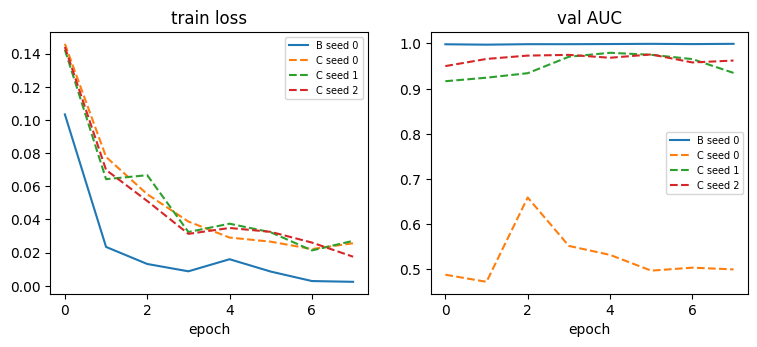

In [6]:
# train loss / val AUC per epoch: shows overfitting and seed spread
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for s, h in [(0, hist_B)]:
    axes[0].plot([l for l, _ in h], label=f"B seed {s}")
    axes[1].plot([a for _, a in h], label=f"B seed {s}")
for s in (0, 1, 2):
    axes[0].plot([l for l, _ in hist_C[s]], "--", label=f"C seed {s}")
    axes[1].plot([a for _, a in hist_C[s]], "--", label=f"C seed {s}")
axes[0].set_title("train loss"); axes[1].set_title("val AUC")
for a in axes: a.set_xlabel("epoch"); a.legend(fontsize=7)
fig.savefig(OUT / "03_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## f · Save the numbers
The comparison table (with the template's reported number as a reference line) and the per-image probabilities for notebook 04.

In [7]:
# comparison table for the report + per-image probabilities for notebook 04
lines = ["# 03 · CNN on the patient-clean split", "",
         "reference: template frozen balanced (image split, argmax): 85.6 % acc, 381/390, 153/234", "",
         "| config | seeds | threshold rule | threshold (seed 0) | test acc | test sens (k/n) | test spec (k/n) | test AUC (seed 0) | test AUC mean +/- sd | val AUC mean | train time/run |",
         "|---|---|---|---|---|---|---|---|---|---|---|"]
for name in CONFIGS:
    r = RES[name]; c = CONFIGS[name]
    sd_txt = f"{r['test_auc_mean']:.3f} +/- {r['test_auc_sd']:.3f}" if len(c["seeds"]) > 1 else f"{r['test_auc_mean']:.3f} (1 seed)"
    for rule, t, m in [(">= 0.5", "0.500", r["argmax"]), ("val sens >= 0.95", f"{r['t_val']:.3f}", r["valthr"])]:
        s, n = m["sens"]; sp, ns = m["spec"]
        lines.append(f"| {name} | {len(c['seeds'])} | {rule} | {t} | {m['acc']:.1%} | {s}/{n} | {sp}/{ns} | "
                     f"{r['test_auc0']:.3f} | {sd_txt} | {r['val_auc_mean']:.3f} | {c['t_run']:.0f}s |")
table = "\n".join(lines)
(OUT / "03_models.md").write_text(table); print(table)

with open(OUT / "03_probs.csv", "w", newline="") as fh:
    wcsv = csv.writer(fh); wcsv.writerow(["file", "split", "label", "p_frozen", "p_ft", "p_ft_aug"])
    for i in np.concatenate([IDX["val"], IDX["test"]]):
        wcsv.writerow([files[i], split[i], y[i], f"{P_frozen[0][i]:.4f}", f"{P_ft[i]:.4f}", f"{P_ftaug[0][i]:.4f}"])
print("wrote", OUT / "03_probs.csv")

# 03 · CNN on the patient-clean split

reference: template frozen balanced (image split, argmax): 85.6 % acc, 381/390, 153/234

| config | seeds | threshold rule | threshold (seed 0) | test acc | test sens (k/n) | test spec (k/n) | test AUC (seed 0) | test AUC mean +/- sd | val AUC mean | train time/run |
|---|---|---|---|---|---|---|---|---|---|---|
| frozen (A) | 3 | >= 0.5 | 0.500 | 83.2% | 384/390 | 135/234 | 0.954 | 0.954 +/- 0.000 | 0.994 | 1s |
| frozen (A) | 3 | val sens >= 0.95 | 0.700 | 85.7% | 379/390 | 156/234 | 0.954 | 0.954 +/- 0.000 | 0.994 | 1s |
| finetuned (B) | 1 | >= 0.5 | 0.500 | 77.6% | 390/390 | 94/234 | 0.943 | 0.943 (1 seed) | 0.999 | 153s |
| finetuned (B) | 1 | val sens >= 0.95 | 0.996 | 88.5% | 380/390 | 172/234 | 0.943 | 0.943 (1 seed) | 0.999 | 153s |
| finetuned+aug (C) | 3 | >= 0.5 | 0.500 | 62.5% | 390/390 | 0/234 | 0.667 | 0.809 +/- 0.125 | 0.871 | 150s |
| finetuned+aug (C) | 3 | val sens >= 0.95 | 1.000 | 63.6% | 387/390 | 10/234 | 0.667 | 0.809 +/- 

In [8]:
import zipfile
from pathlib import Path
from google.colab import files

# Colab-only helper: zip results and the checkpoint for download
out = Path("/content/nb03_outputs.zip")
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for f in Path("/content/results/own").glob("03_*"):          # 03_models.md, 03_curves.png, 03_probs.csv, 03_final_choice.json
        z.write(f, f"results/own/{f.name}")
    ckpt = Path("/content/models/03_final.pt")
    if ckpt.exists():
        z.write(ckpt, "data/models/03_final.pt")                   # needed by notebook 04 (gitignored)
    else:
        print("WARNING: /content/models/03_final.pt not found")

with zipfile.ZipFile(out) as z:
    for i in z.infolist(): print(f"{i.file_size/1e6:8.2f} MB  {i.filename}")
files.download(str(out))

    0.08 MB  results/own/03_curves.png
    0.00 MB  results/own/03_models.md
    0.09 MB  results/own/03_probs.csv
    0.00 MB  results/own/03_final_choice.json
   44.79 MB  data/models/03_final.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What I learned

- Fine-tuning the whole ResNet-18 at 224 px gave the best specificity at the same sensitivity: with the threshold chosen on validation (sensitivity ≥ 95 %), it found 380/390 pneumonias and got 172/234 normals right (88.5 % accuracy), against 379/390 and 156/234 for the frozen model and 381/390 and 153/234 for the template. But its test AUC (0.943, one seed) is not higher than the frozen model's (0.954): most of the gain comes from choosing the threshold on validation, not from better ranking.
- My validation set is much easier than the test set: validation AUC 0.994 (frozen) and 0.999 (fine-tuned), test AUC 0.954 and 0.943. Validation comes from the same official training folder; the test set seems to differ in distribution. So the val-chosen threshold for the fine-tuned model is extreme (0.996), the model is very over-confident at the default 0.5 (390/390 pneumonia, only 94/234 normals), and selection by validation AUC is close to its ceiling.
- My first augmentation run (config C) failed because of a bug, not because augmentation does not help: I applied ColorJitter after ImageNet normalisation, and ColorJitter clips values to [0, 1], so the training images lost their dark range and no longer looked like the validation images (seed 0 stayed at chance, val AUC ≈ 0.5). Lesson: augment on pixel values in [0, 1], then normalise; and always look at per-seed curves, not only means.

Next: `04_evaluation.ipynb` evaluates the chosen checkpoint (`03_final_choice.json`) with bootstrap intervals, calibration and Grad-CAM.